# Early Wildfire Detection — U-Net (Track B)

Trains a small U-Net on the patch dataset produced by `forest_fire_detection_v2.ipynb`
(Phases 1-5), predicting the same FIRMS-derived fire mask the Random Forest baseline
was evaluated against. Goal: beat the RF baseline's **IoU 0.339** (at its tuned
threshold) by using spatial context, which a per-pixel classifier structurally cannot.

**Prerequisite:** run the patch materialization cell (added to the end of the v2
notebook) first, so `./patches/manifest.csv` and the `.npz` patch files exist. This
notebook only reads from `./patches/` — it never touches the raw `.jp2` satellite
files, which is the whole point of materializing patches ahead of time.

**Install note:** this notebook needs PyTorch. If you don't have it:
```
pip install torch
```
(CPU-only is fine to get started; if you have an NVIDIA GPU with CUDA set up, training
will be substantially faster — the notebook auto-detects and uses GPU if available.)


## 1. Setup

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import precision_recall_fscore_support, jaccard_score, precision_recall_curve

print("PyTorch:", torch.__version__)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


PyTorch: 2.11.0+cu128
Using device: cuda


In [2]:
# ----- CONFIG -----
PATCHES_DIR = "./patches"

# Same held-out dates as the Random Forest notebook (v2), for a fair comparison.
# With 10 dates now available, holding out two spanning different fire stages is more
# robust than a single date -- keep this in sync with TEST_DATES in the v2 notebook.
TEST_DATES = ["20210822", "20210906"]

BATCH_SIZE = 8
EPOCHS = 30
LEARNING_RATE = 1e-3
BASE_CHANNELS = 32         # U-Net width. Lower (e.g. 16) if training is too slow/memory-heavy;
                            # raise (e.g. 64) if you have a GPU and want more capacity.
IN_CHANNELS = 8             # B04, B11, B12, B8A, NDVI, NBR, NBR2, MIRBI -- matches the RF baseline

RNG_SEED = 42
torch.manual_seed(RNG_SEED)
np.random.seed(RNG_SEED)


## 2. Dataset

Each `.npz` file has `X` (patch_size, patch_size, 8), `mask` (patch_size, patch_size,
binary FIRMS label), and `valid` (patch_size, patch_size, cloud/shadow validity from
SCL). The `valid` mask is threaded all the way through to the loss function and metrics
so cloudy pixels never contribute to training or evaluation — same principle as the RF
baseline, just at the patch level instead of per-pixel.

In [3]:
class PatchDataset(Dataset):
    def __init__(self, manifest_df, patches_dir):
        self.df = manifest_df.reset_index(drop=True)
        self.dir = patches_dir

    def __len__(self):
        return len(self.df)

    def __getitem__(self, i):
        row = self.df.iloc[i]
        d = np.load(os.path.join(self.dir, row.file))
        X = torch.from_numpy(d["X"]).permute(2, 0, 1).float()       # (8, H, W)
        y = torch.from_numpy(d["mask"]).float()                      # (H, W)
        v = torch.from_numpy(d["valid"].astype("float32"))           # (H, W)
        return X, y, v

manifest = pd.read_csv(os.path.join(PATCHES_DIR, "manifest.csv"), dtype={"date": str})
print(f"Total materialized patches: {len(manifest)}")
print(manifest.groupby(["date", "label"]).size())


Total materialized patches: 16761
date      label
20210713  0        1760
          1           4
20210718  0        1716
          1          43
20210728  0        1531
          1          68
20210802  0        1668
          1          87
20210812  0        1403
          1          89
20210822  0        1641
          1          93
20210827  0        1639
          1          83
20210901  0        1655
          1          99
20210906  0        1362
          1          56
20210911  0        1751
          1          13
dtype: int64


## 3. Train/test split — by date, same as the Random Forest baseline

Held-out date matches `TEST_DATE` from the RF notebook (`20210822`), so the IoU numbers
are directly comparable between the two models.

In [4]:
train_df = manifest[~manifest.date.isin(TEST_DATES)]
test_df = manifest[manifest.date.isin(TEST_DATES)]

print(f"Train: {len(train_df)} patches from {sorted(train_df.date.unique())}")
print(f"Test:  {len(test_df)} patches from {sorted(test_df.date.unique())}")
print(f"Train fire-patch fraction: {train_df.label.mean():.3f}")

train_ds = PatchDataset(train_df, PATCHES_DIR)
test_ds = PatchDataset(test_df, PATCHES_DIR)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)


Train: 13609 patches from ['20210713', '20210718', '20210728', '20210802', '20210812', '20210827', '20210901', '20210911']
Test:  3152 patches from ['20210822', '20210906']
Train fire-patch fraction: 0.036


## 4. Model — small U-Net

Standard encoder-decoder with skip connections, kept intentionally small (2 downsampling
steps, `BASE_CHANNELS` width) since the training set here is still modest (tens to low
hundreds of patches until more Sentinel-2 dates are pulled in). A bigger network on this
little data would just overfit harder, not perform better.

In [5]:
class ConvBlock(nn.Module):
    def __init__(self, cin, cout):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(cin, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
            nn.Conv2d(cout, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
        )
    def forward(self, x):
        return self.net(x)

class UNet(nn.Module):
    def __init__(self, in_ch=IN_CHANNELS, base=BASE_CHANNELS):
        super().__init__()
        self.enc1 = ConvBlock(in_ch, base)
        self.pool1 = nn.MaxPool2d(2)
        self.enc2 = ConvBlock(base, base * 2)
        self.pool2 = nn.MaxPool2d(2)
        self.bottleneck = ConvBlock(base * 2, base * 4)
        self.up2 = nn.ConvTranspose2d(base * 4, base * 2, 2, stride=2)
        self.dec2 = ConvBlock(base * 4, base * 2)
        self.up1 = nn.ConvTranspose2d(base * 2, base, 2, stride=2)
        self.dec1 = ConvBlock(base * 2, base)
        self.out = nn.Conv2d(base, 1, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))
        b = self.bottleneck(self.pool2(e2))
        d2 = self.dec2(torch.cat([self.up2(b), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        return self.out(d1).squeeze(1)   # (B, H, W) logits -- apply sigmoid for probabilities

model = UNet().to(device)
n_params = sum(p.numel() for p in model.parameters())
print(f"Model parameters: {n_params:,}")


Model parameters: 469,249


## 5. Loss function

Binary cross-entropy computed per-pixel, then masked by `valid` before averaging — cloudy
pixels contribute zero gradient, same principle as excluding them from RF training rows.
A `pos_weight` up-weights the rare fire class, similar in spirit to the RF's negative
subsampling, but applied as a loss weight instead of a sampling ratio since patches (not
individual pixels) are the training unit here.

In [6]:
# Estimate a reasonable pos_weight from the training set's actual fire-pixel prevalence
sample_fracs = []
for f in train_df.file.sample(min(30, len(train_df)), random_state=RNG_SEED):
    d = np.load(os.path.join(PATCHES_DIR, f))
    v = d["valid"].astype(bool)
    if v.sum() > 0:
        sample_fracs.append(d["mask"][v].mean())
fire_prevalence = max(np.mean(sample_fracs), 1e-4)
pos_weight_value = min((1 - fire_prevalence) / fire_prevalence, 50.0)  # cap to avoid instability
print(f"Estimated fire-pixel prevalence in training patches: {fire_prevalence:.4f}")
print(f"Using pos_weight: {pos_weight_value:.1f}")

pos_weight = torch.tensor(pos_weight_value, device=device)

def masked_bce_loss(logits, y, valid):
    loss_map = F.binary_cross_entropy_with_logits(logits, y, pos_weight=pos_weight, reduction="none")
    return (loss_map * valid).sum() / valid.sum().clamp(min=1)


Estimated fire-pixel prevalence in training patches: 0.0370
Using pos_weight: 26.0


## 6. Training loop

epoch   0  train_loss 0.4375  val_loss 0.4011
epoch   5  train_loss 0.3126  val_loss 0.3958
epoch  10  train_loss 0.2711  val_loss 0.3392
epoch  15  train_loss 0.2546  val_loss 0.3064
epoch  20  train_loss 0.2453  val_loss 0.3223
epoch  25  train_loss 0.2357  val_loss 0.2967
epoch  29  train_loss 0.2245  val_loss 0.3024

Best val_loss: 0.2829 -- loaded best checkpoint


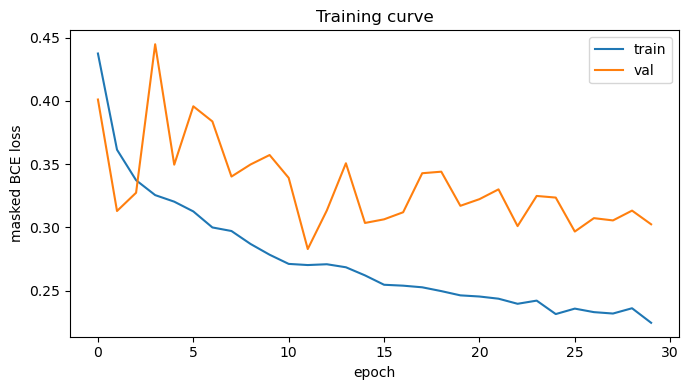

In [7]:
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=3)

history = {"train_loss": [], "val_loss": []}
best_val_loss = float("inf")
best_state = None

for epoch in range(EPOCHS):
    model.train()
    train_loss = 0.0
    for X, y, v in train_loader:
        X, y, v = X.to(device), y.to(device), v.to(device)
        logits = model(X)
        loss = masked_bce_loss(logits, y, v)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * X.size(0)
    train_loss /= len(train_ds)

    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for X, y, v in test_loader:
            X, y, v = X.to(device), y.to(device), v.to(device)
            logits = model(X)
            loss = masked_bce_loss(logits, y, v)
            val_loss += loss.item() * X.size(0)
    val_loss /= max(len(test_ds), 1)

    scheduler.step(val_loss)
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}

    if epoch % 5 == 0 or epoch == EPOCHS - 1:
        print(f"epoch {epoch:3d}  train_loss {train_loss:.4f}  val_loss {val_loss:.4f}")

model.load_state_dict(best_state)
print(f"\nBest val_loss: {best_val_loss:.4f} -- loaded best checkpoint")

plt.figure(figsize=(7, 4))
plt.plot(history["train_loss"], label="train")
plt.plot(history["val_loss"], label="val")
plt.xlabel("epoch"); plt.ylabel("masked BCE loss"); plt.legend(); plt.title("Training curve")
plt.tight_layout()
plt.show()


## 7. Evaluate on the held-out date

Same metrics as the Random Forest baseline (Precision/Recall/F1/IoU), computed pixel-wise
across all test patches, valid pixels only. Also runs the same threshold-tuning approach
used for the RF, so the comparison is apples-to-apples at both the default 0.5 cutoff and
each model's own best-F1 threshold.

Default threshold (0.5) -- combined, all held-out dates: precision=0.257  recall=0.763  f1=0.385  iou=0.238
Best-F1 threshold (0.715) -- combined: precision=0.571  recall=0.590  f1=0.580  iou=0.409

--- Per-date breakdown (tuned threshold 0.715) ---
  20210822: precision=0.504  recall=0.547  f1=0.525  iou=0.356
  20210906: precision=0.653  recall=0.636  f1=0.645  iou=0.476

--- Compare these numbers against the Random Forest results from the v2 notebook ---
(rerun the v2 notebook first -- its RF numbers will also change with 10 dates,
 so don't compare against the old 4-date RF numbers: precision=0.469 iou=0.339)


C:\Users\HP\AppData\Local\Temp\ipykernel_40108\158360726.py:60: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.legend(); plt.tight_layout(); plt.show()
c:\Users\HP\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


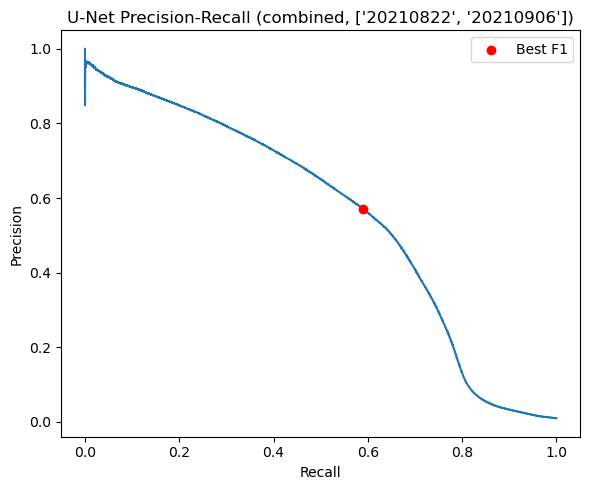

In [8]:
model.eval()
# NOTE: DataLoader batches don't carry the date label through by default, so we track
# it separately via test_df's row order (shuffle=False on test_loader preserves order).
all_prob, all_true, all_valid = [], [], []
with torch.no_grad():
    for X, y, v in test_loader:
        logits = model(X.to(device))
        prob = torch.sigmoid(logits).cpu().numpy()
        all_prob.append(prob)
        all_true.append(y.numpy())
        all_valid.append(v.numpy())

all_prob = np.concatenate(all_prob)      # (N, H, W)
all_true = np.concatenate(all_true).astype(int)
all_valid = np.concatenate(all_valid).astype(bool)
test_dates_per_patch = test_df.date.values  # aligned with all_prob/all_true since shuffle=False

prob_flat, true_flat, valid_flat = all_prob.ravel(), all_true.ravel(), all_valid.ravel()
prob_v, true_v = prob_flat[valid_flat], true_flat[valid_flat]

pred_default = (prob_v >= 0.5).astype(int)
p50, r50, f150, _ = precision_recall_fscore_support(true_v, pred_default, average="binary", zero_division=0)
iou50 = jaccard_score(true_v, pred_default, zero_division=0)
print(f"Default threshold (0.5) -- combined, all held-out dates: precision={p50:.3f}  recall={r50:.3f}  f1={f150:.3f}  iou={iou50:.3f}")

prec, rec, thresh = precision_recall_curve(true_v, prob_v)
prec, rec = prec[:-1], rec[:-1]
f1s = 2 * prec * rec / (prec + rec + 1e-9)
best_i = f1s.argmax()
best_t = thresh[best_i]
pred_best = (prob_v >= best_t).astype(int)
p_b, r_b, f1_b, _ = precision_recall_fscore_support(true_v, pred_best, average="binary", zero_division=0)
iou_b = jaccard_score(true_v, pred_best, zero_division=0)
print(f"Best-F1 threshold ({best_t:.3f}) -- combined: precision={p_b:.3f}  recall={r_b:.3f}  f1={f1_b:.3f}  iou={iou_b:.3f}")

print(f"\n--- Per-date breakdown (tuned threshold {best_t:.3f}) ---")
for d in TEST_DATES:
    d_mask = (test_dates_per_patch == d)
    if d_mask.sum() == 0:
        continue
    d_valid = all_valid[d_mask].ravel()
    d_true = all_true[d_mask].ravel()[d_valid]
    d_prob = all_prob[d_mask].ravel()[d_valid]
    if len(d_true) == 0 or d_true.sum() == 0:
        print(f"  {d}: no fire pixels in this held-out date's valid area, skipping")
        continue
    d_pred = (d_prob >= best_t).astype(int)
    p_d, r_d, f1_d, _ = precision_recall_fscore_support(d_true, d_pred, average="binary", zero_division=0)
    iou_d = jaccard_score(d_true, d_pred, zero_division=0)
    print(f"  {d}: precision={p_d:.3f}  recall={r_d:.3f}  f1={f1_d:.3f}  iou={iou_d:.3f}")

print("\n--- Compare these numbers against the Random Forest results from the v2 notebook ---")
print("(rerun the v2 notebook first -- its RF numbers will also change with 10 dates,")
print(" so don't compare against the old 4-date RF numbers: precision=0.469 iou=0.339)")

plt.figure(figsize=(6, 5))
plt.plot(rec, prec)
plt.scatter(rec[best_i], prec[best_i], color="red", zorder=5, label="Best F1")
plt.xlabel("Recall"); plt.ylabel("Precision"); plt.title(f"U-Net Precision-Recall (combined, {TEST_DATES})")
plt.legend(); plt.tight_layout(); plt.show()


## 8. Visual comparison — a few test patches

Shows the input composite, ground truth, and prediction side by side for a handful of
test patches — the qualitative check for whether the model is producing spatially
coherent fire regions (the whole point of moving to a CNN) rather than the speckled,
independent-pixel noise a per-pixel Random Forest inherently produces.

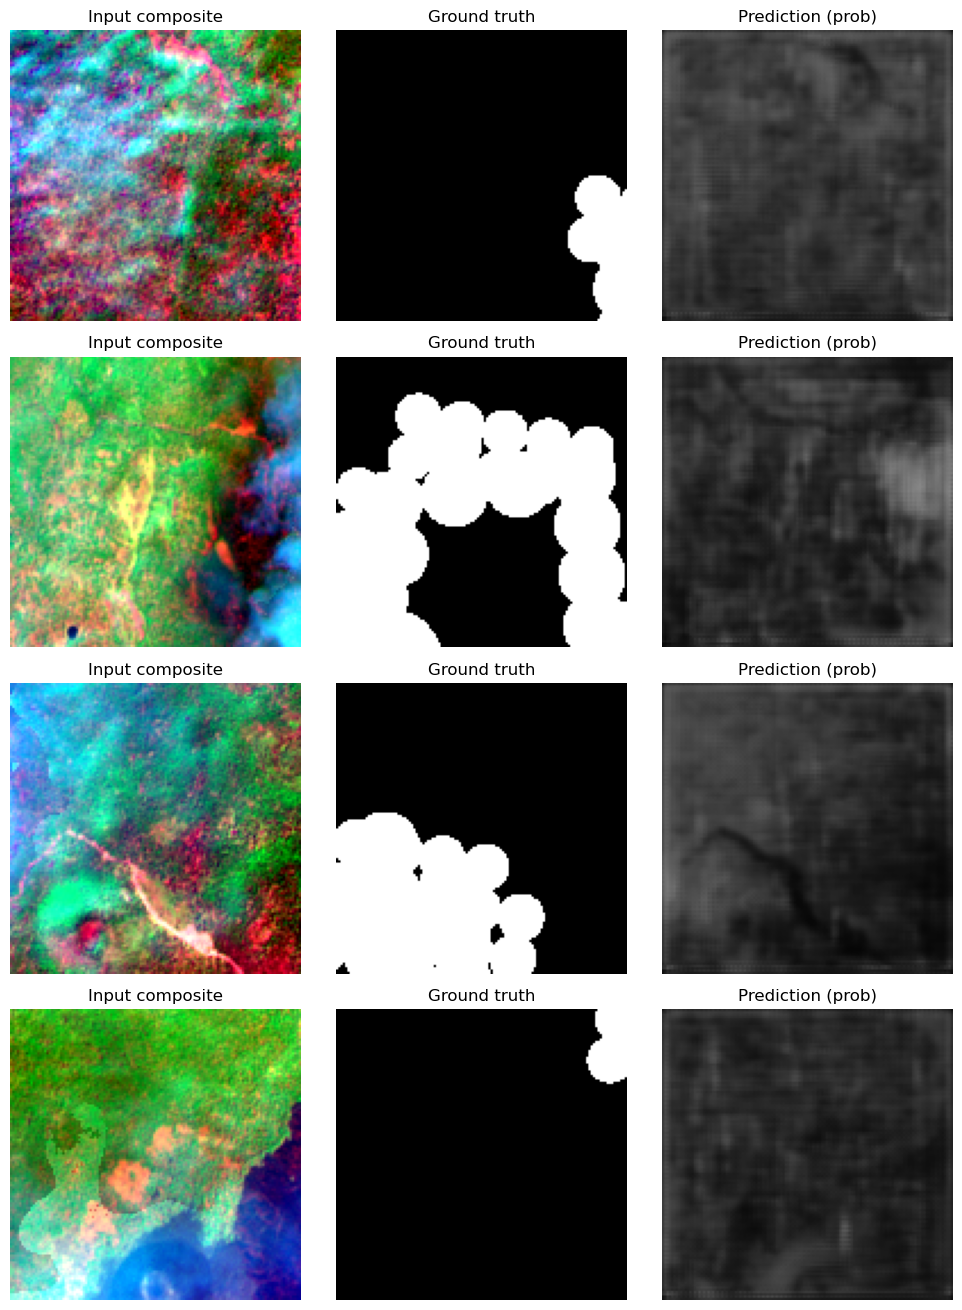

In [9]:
def patch_composite(X):
    """X: (8,H,W) tensor -> SWIR2/NIR/Red RGB-ish composite for display."""
    def stretch(x):
        x = x.numpy()
        lo, hi = np.percentile(x, [2, 98])
        return np.clip((x - lo) / (hi - lo + 1e-6), 0, 1)
    r, g, b = stretch(X[2]), stretch(X[3]), stretch(X[0])   # B12, B8A, B04
    return np.dstack([r, g, b])

fire_indices = [i for i in range(len(test_ds)) if test_ds.df.iloc[i].label == 1]
other_indices = [i for i in range(len(test_ds)) if i not in fire_indices]
show_indices = (fire_indices + other_indices)[:4]

n_show = min(4, len(show_indices))
fig, axes = plt.subplots(n_show, 3, figsize=(10, 3.3 * n_show))
if n_show == 1:
    axes = axes[None, :]

model.eval()
with torch.no_grad():
    for row_i, idx in enumerate(show_indices):
        X, y, v = test_ds[idx]
        prob = torch.sigmoid(model(X.unsqueeze(0).to(device))).cpu().squeeze(0).numpy()

        axes[row_i, 0].imshow(patch_composite(X)); axes[row_i, 0].set_title("Input composite"); axes[row_i, 0].axis("off")
        axes[row_i, 1].imshow(y.numpy(), cmap="gray", vmin=0, vmax=1); axes[row_i, 1].set_title("Ground truth"); axes[row_i, 1].axis("off")
        axes[row_i, 2].imshow(prob, cmap="gray", vmin=0, vmax=1); axes[row_i, 2].set_title("Prediction (prob)"); axes[row_i, 2].axis("off")

plt.tight_layout()
plt.show()


## 9. Save the trained model

In [13]:
os.makedirs("./models", exist_ok=True)
torch.save({
    "model_state_dict": model.state_dict(),
    "config": {
        "in_channels": IN_CHANNELS, "base_channels": BASE_CHANNELS,
        "test_dates": TEST_DATES, "pos_weight": pos_weight_value,
    },
}, "./models/unet_wildfire_v2.pt")
print("Saved to ./models/unet_wildfire_v2.pt")

Saved to ./models/unet_wildfire_v2.pt


## 10. Discussion & next steps

- **Directly compare the IoU printed in Section 7 against the RF baseline (0.339 at its
  tuned threshold).** If the U-Net wins, that confirms spatial context genuinely helps,
  as expected. If it doesn't yet, the most likely cause is dataset size — the patch
  count from 4 dates on 1 tile is still small for a CNN; pulling the remaining
  Copernicus scenes across the FIRMS coverage window (as planned) is the next lever to
  pull before concluding the architecture is wrong.
- **Precision vs. recall trade-off**: same as the RF, check whether `pos_weight` is
  over- or under-correcting — lower it if the model over-predicts fire everywhere
  (mirrors the `class_weight="balanced"` lesson from the RF baseline), raise it if the
  model is too conservative and recall is very low.
- **Lead-time analysis** — the actual "early detection" claim — still applies once more
  dates are added: check whether the model's probability crosses threshold at a pixel
  *before* FIRMS/official perimeter data shows fire there, not just whether it agrees
  with FIRMS on the same day.
- **FRP-weighted evaluation** — `frp_{date}.tif` (saved by the v2 notebook) isn't used
  yet here; a natural extension is weighting the loss or a secondary evaluation by FRP,
  so getting high-intensity fire pixels right counts for more than borderline ones.
